# Experiment 6: Implementation of the Word Count Application Using Hadoop MapReduce

**Aim:** To implement the Word Count application using Hadoop MapReduce and analyze the frequency of words in a text file.

**Mapped CO(s):** CO2, CO3

## 1. Import Required Libraries

In [1]:
import os
import shutil
import subprocess
import time
from io import StringIO
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

## 2. MapReduce Word Count (Brief Theory)

MapReduce splits a big job into small tasks that run in parallel.

| Phase | Input | Output (Word Count) |
|---|---|---|
| **Map** | One line of text | `(word, 1)` for every word |
| **Combine** (optional) | `(word, [1, 1, ...])` on one mapper | `(word, partial sum)` |
| **Shuffle & Sort** | All mapper outputs | Values grouped by word |
| **Reduce** | `(word, [1, 1, 1])` | `(word, total count)` |

Example for the line `Hadoop uses MapReduce`:

- Mapper emits `(hadoop, 1)`, `(uses, 1)`, `(mapreduce, 1)`
- Reducer receives `(hadoop, [1, 1])` from all lines and writes `(hadoop, 2)`

The program lowercases text and removes punctuation, so `Hadoop` and `hadoop.` count as the same word.

## 3. Set Java and Hadoop Environment

In [2]:
EXP_DIR = Path("/Users/ojas/Desktop/DS Lab/Experiment6")
SRC_DIR = EXP_DIR / "src"

WORK_DIR = Path("/tmp/exp6")
LOCAL_DIR = WORK_DIR / "local"
BUILD_DIR = WORK_DIR / "build"
HDFS_DATA = WORK_DIR / "hdfs-data"
CONF_DIR = WORK_DIR / "hadoop-conf"
LOG_DIR = WORK_DIR / "logs"
JAR_PATH = WORK_DIR / "wordcount.jar"

JAVA_HOME = Path("/opt/homebrew/opt/openjdk@17/libexec/openjdk.jdk/Contents/Home")
HADOOP_HOME = Path("/Users/ojas/hadoop-3.4.1")

os.environ["JAVA_HOME"] = str(JAVA_HOME)
os.environ["HADOOP_HOME"] = str(HADOOP_HOME)
os.environ["HADOOP_CONF_DIR"] = str(CONF_DIR)
os.environ["HADOOP_LOG_DIR"] = str(LOG_DIR)
os.environ["PATH"] = (
    f"{JAVA_HOME / 'bin'}:{HADOOP_HOME / 'bin'}:{HADOOP_HOME / 'sbin'}:"
    + os.environ["PATH"]
)

for folder in (LOCAL_DIR, LOG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

for src in (EXP_DIR / "local_files").glob("*.txt"):
    shutil.copy2(src, LOCAL_DIR / src.name)


NOISE = ("NativeCodeLoader", "log4j", "WARN ")


def clean(text):
    return "\n".join(
        line for line in (text or "").splitlines()
        if not any(word in line for word in NOISE)
    ).strip()


def capture(cmd, check=True):
    result = subprocess.run(
        cmd, shell=True, text=True, capture_output=True, env=os.environ.copy()
    )
    if check and result.returncode != 0:
        print(result.stdout)
        print(result.stderr)
        raise RuntimeError(f"Command failed with exit code {result.returncode}: {cmd}")
    return result


def run(cmd, check=True):
    print(f"$ {cmd}")
    result = capture(cmd, check)
    for text in (clean(result.stdout), clean(result.stderr)):
        if text:
            print(text)


run("java -version")
print()
run("hadoop version | head -1")

$ java -version
openjdk version "17.0.19" 2026-04-21
OpenJDK Runtime Environment Homebrew (build 17.0.19+0)
OpenJDK 64-Bit Server VM Homebrew (build 17.0.19+0, mixed mode, sharing)

$ hadoop version | head -1


Hadoop 3.4.1


## 4. Configure and Start HDFS

Single-node setup: `fs.defaultFS = hdfs://localhost:9000`, replication = 1.

In [3]:
if CONF_DIR.exists():
    shutil.rmtree(CONF_DIR)
shutil.copytree(HADOOP_HOME / "etc" / "hadoop", CONF_DIR)

(CONF_DIR / "core-site.xml").write_text("""<?xml version="1.0" encoding="UTF-8"?>
<configuration>
  <property>
    <name>fs.defaultFS</name>
    <value>hdfs://localhost:9000</value>
  </property>
</configuration>
""")

(CONF_DIR / "hdfs-site.xml").write_text(f"""<?xml version="1.0" encoding="UTF-8"?>
<configuration>
  <property><name>dfs.replication</name><value>1</value></property>
  <property><name>dfs.namenode.name.dir</name><value>file://{HDFS_DATA / 'namenode'}</value></property>
  <property><name>dfs.datanode.data.dir</name><value>file://{HDFS_DATA / 'datanode'}</value></property>
  <property><name>dfs.namenode.http-address</name><value>localhost:9870</value></property>
  <property><name>dfs.datanode.address</name><value>localhost:9866</value></property>
  <property><name>dfs.datanode.http.address</name><value>localhost:9864</value></property>
  <property><name>dfs.datanode.ipc.address</name><value>localhost:9867</value></property>
  <property><name>dfs.permissions.enabled</name><value>false</value></property>
</configuration>
""")

(CONF_DIR / "mapred-site.xml").write_text("""<?xml version="1.0" encoding="UTF-8"?>
<configuration>
  <property>
    <name>mapreduce.framework.name</name>
    <value>local</value>
  </property>
</configuration>
""")

capture("hdfs --daemon stop datanode", check=False)
capture("hdfs --daemon stop namenode", check=False)
time.sleep(2)
if HDFS_DATA.exists():
    shutil.rmtree(HDFS_DATA)
HDFS_DATA.mkdir(parents=True)

capture("hdfs namenode -format -force -nonInteractive")
print("NameNode formatted.")
run("hdfs --daemon start namenode")
run("hdfs --daemon start datanode")

for _ in range(30):
    time.sleep(1)
    report = capture("hdfs dfsadmin -report", check=False)
    if "Live datanodes (1)" in report.stdout:
        break

run("jps")

NameNode formatted.
$ hdfs --daemon start namenode


$ hdfs --daemon start datanode


$ jps
13989 DataNode
14038 Jps
13928 NameNode


## 5. Create the Input File and Upload It to HDFS

In [4]:
print("--- input.txt ---")
print((LOCAL_DIR / "input.txt").read_text())

run("hdfs dfs -mkdir -p /user/lab6/input")
run(f"hdfs dfs -put -f {LOCAL_DIR / 'input.txt'} /user/lab6/input/")
run("hdfs dfs -ls /user/lab6/input")

--- input.txt ---
Hadoop is a big data framework.
Hadoop uses MapReduce.
MapReduce processes big data efficiently.

$ hdfs dfs -mkdir -p /user/lab6/input


$ hdfs dfs -put -f /tmp/exp6/local/input.txt /user/lab6/input/


$ hdfs dfs -ls /user/lab6/input


Found 1 items
-rw-r--r--   1 ojas supergroup         97 2026-10-01 23:24 /user/lab6/input/input.txt


## 6. Word Count MapReduce Program (Java)

The program has three parts:

- **`TokenizerMapper`**: lowercases each line, removes punctuation, and emits `(word, 1)`. If `wordcount.skip.stopwords=true`, common words are skipped.
- **`IntSumReducer`**: adds up all the 1s for a word. It is also used as the **combiner**.
- **Driver (`run` / `main`)**: configures the job, sets input/output paths in HDFS, and submits it.

In [5]:
print((SRC_DIR / "WordCount.java").read_text())

import java.io.IOException;
import java.util.Arrays;
import java.util.HashSet;
import java.util.Locale;
import java.util.Set;
import java.util.StringTokenizer;

import org.apache.hadoop.conf.Configuration;
import org.apache.hadoop.conf.Configured;
import org.apache.hadoop.fs.Path;
import org.apache.hadoop.io.IntWritable;
import org.apache.hadoop.io.LongWritable;
import org.apache.hadoop.io.Text;
import org.apache.hadoop.mapreduce.Job;
import org.apache.hadoop.mapreduce.Mapper;
import org.apache.hadoop.mapreduce.Reducer;
import org.apache.hadoop.mapreduce.lib.input.FileInputFormat;
import org.apache.hadoop.mapreduce.lib.output.FileOutputFormat;
import org.apache.hadoop.util.Tool;
import org.apache.hadoop.util.ToolRunner;

public class WordCount extends Configured implements Tool {

    public static final String SKIP_STOPWORDS = "wordcount.skip.stopwords";

    public static class TokenizerMapper extends Mapper<LongWritable, Text, Text, IntWritable> {

        private static final IntWr

## 7. Compile the Program and Create the JAR File

In [6]:
if BUILD_DIR.exists():
    shutil.rmtree(BUILD_DIR)
BUILD_DIR.mkdir(parents=True)
shutil.copy2(SRC_DIR / "WordCount.java", BUILD_DIR / "WordCount.java")

run(f'javac -classpath "$(hadoop classpath)" -d {BUILD_DIR} {BUILD_DIR / "WordCount.java"}')
run(f"jar cf {JAR_PATH} -C {BUILD_DIR} .")
run(f"jar tf {JAR_PATH}")

$ javac -classpath "$(hadoop classpath)" -d /tmp/exp6/build /tmp/exp6/build/WordCount.java


$ jar cf /tmp/exp6/wordcount.jar -C /tmp/exp6/build .
$ jar tf /tmp/exp6/wordcount.jar
META-INF/
META-INF/MANIFEST.MF
WordCount$IntSumReducer.class
WordCount$TokenizerMapper.class
WordCount.class
WordCount.java


## 8. Execute the MapReduce Job

`run_wordcount` submits the JAR with `hadoop jar`, prints the important job counters, and loads the HDFS output into a table.

In [7]:
KEY_COUNTERS = (
    "completed successfully",
    "Map input records",
    "Map output records",
    "Combine input records",
    "Combine output records",
    "Reduce input groups",
    "Reduce output records",
)


def read_output(hdfs_dir):
    result = capture(f"hdfs dfs -cat {hdfs_dir}/part-r-*")
    df = pd.read_csv(
        StringIO(clean(result.stdout)), sep="\t", header=None, names=["word", "count"]
    )
    return df.sort_values(["count", "word"], ascending=[False, True]).reset_index(drop=True)


def run_wordcount(hdfs_input, hdfs_output, skip_stopwords=False):
    capture(f"hdfs dfs -rm -r -f {hdfs_output}")
    opts = "-D wordcount.skip.stopwords=true " if skip_stopwords else ""
    cmd = f"hadoop jar {JAR_PATH} WordCount {opts}{hdfs_input} {hdfs_output}"
    print(f"$ {cmd}")
    result = capture(cmd)
    seen = set()
    for line in (result.stdout + "\n" + result.stderr).splitlines():
        if any(key in line for key in KEY_COUNTERS):
            msg = line.split(" - ")[-1].strip()
            if msg.split("=")[0] not in seen and not msg.endswith("=0"):
                seen.add(msg.split("=")[0])
                print("   ", msg)
    return read_output(hdfs_output)


wc_original = run_wordcount("/user/lab6/input/input.txt", "/user/lab6/output")

$ hadoop jar /tmp/exp6/wordcount.jar WordCount /user/lab6/input/input.txt /user/lab6/output


    Map input records=3
    Map output records=14
    Combine input records=14
    Combine output records=10
    Reduce input groups=10
    Reduce output records=10
    Job job_local600822020_0001 completed successfully


## 9. Display the Output (Word Frequencies)

In [8]:
run("hdfs dfs -ls /user/lab6/output")
print()
run("hdfs dfs -cat /user/lab6/output/part-r-00000")

$ hdfs dfs -ls /user/lab6/output


Found 2 items
-rw-r--r--   1 ojas supergroup          0 2026-10-01 23:24 /user/lab6/output/_SUCCESS
-rw-r--r--   1 ojas supergroup         88 2026-10-01 23:24 /user/lab6/output/part-r-00000

$ hdfs dfs -cat /user/lab6/output/part-r-00000


a	1
big	2
data	2
efficiently	1
framework	1
hadoop	2
is	1
mapreduce	2
processes	1
uses	1


Word frequencies (sorted by count):


,word,count
0,big,2
1,data,2
2,hadoop,2
3,mapreduce,2
4,a,1
5,efficiently,1
6,framework,1
7,is,1
8,processes,1
9,uses,1


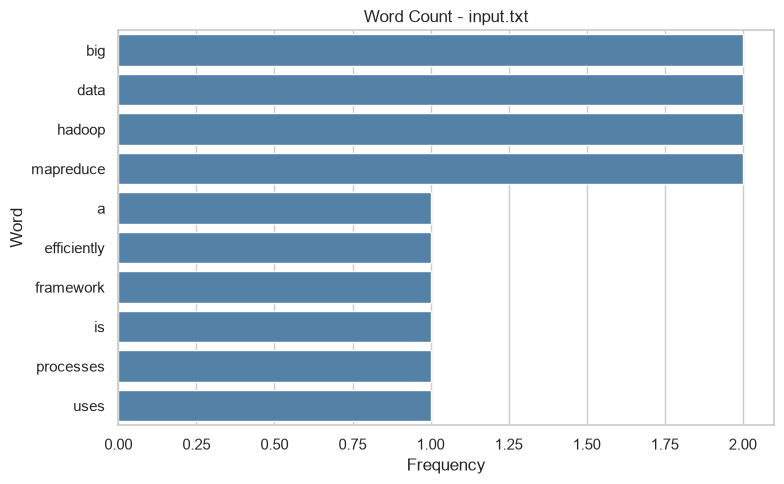

Total words: 14
Unique words: 10


In [9]:
print("Word frequencies (sorted by count):")
display(wc_original)

sns.barplot(data=wc_original, x="count", y="word", color="steelblue")
plt.title("Word Count - input.txt")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()

print("Total words:", wc_original["count"].sum())
print("Unique words:", len(wc_original))

---
## Exercises / Assignments

### Exercise 1: Modify the input file and observe the changes in the output

In [10]:
print("--- input_modified.txt ---")
print((LOCAL_DIR / "input_modified.txt").read_text())

run("hdfs dfs -mkdir -p /user/lab6/input_modified")
run(f"hdfs dfs -put -f {LOCAL_DIR / 'input_modified.txt'} /user/lab6/input_modified/")

wc_modified = run_wordcount("/user/lab6/input_modified", "/user/lab6/output_modified")
display(wc_modified)

--- input_modified.txt ---
Hadoop is a big data framework.
Hadoop uses MapReduce.
MapReduce processes big data efficiently.
HDFS stores big data in blocks.
Hadoop is open source and Hadoop is scalable.

$ hdfs dfs -mkdir -p /user/lab6/input_modified


$ hdfs dfs -put -f /tmp/exp6/local/input_modified.txt /user/lab6/input_modified/


$ hadoop jar /tmp/exp6/wordcount.jar WordCount /user/lab6/input_modified /user/lab6/output_modified


    Map input records=5
    Map output records=28
    Combine input records=28
    Combine output records=18
    Reduce input groups=18
    Reduce output records=18
    Job job_local1606086186_0001 completed successfully


,word,count
0,hadoop,4
1,big,3
2,data,3
3,is,3
4,mapreduce,2
5,a,1
6,and,1
7,blocks,1
8,efficiently,1
9,framework,1


Two lines were added. `hadoop` goes from 2 to 4, `is` from 1 to 3, `big` and `data` from 2 to 3, and new words such as `hdfs`, `blocks`, `scalable`, and `source` appear with count 1. Words in the unchanged lines (`mapreduce`, `framework`, `uses`) keep the same count.

### Exercise 2: Ignore common words such as is, the, and a

In [11]:
wc_no_stop = run_wordcount(
    "/user/lab6/input_modified", "/user/lab6/output_nostop", skip_stopwords=True
)

removed = sorted(set(wc_modified["word"]) - set(wc_no_stop["word"]))
print("\nWords removed as stopwords:", removed)
display(wc_no_stop)

$ hadoop jar /tmp/exp6/wordcount.jar WordCount -D wordcount.skip.stopwords=true /user/lab6/input_modified /user/lab6/output_nostop


    Map input records=5
    Map output records=22
    Combine input records=22
    Combine output records=14
    Reduce input groups=14
    Reduce output records=14
    Job job_local1100068604_0001 completed successfully



Words removed as stopwords: ['a', 'and', 'in', 'is']


,word,count
0,hadoop,4
1,big,3
2,data,3
3,mapreduce,2
4,blocks,1
5,efficiently,1
6,framework,1
7,hdfs,1
8,open,1
9,processes,1


The Mapper checks each word against a stopword list (`a, an, the, is, are, and, of, in, ...`). When `-D wordcount.skip.stopwords=true` is passed, those words are never emitted, so they never reach the Reducer. Only meaningful words remain in the output.

### Exercise 3: Execute the program with another text file

--- another.txt ---
Data science is the study of data to extract useful insights.
Python and Hadoop are popular tools in data science.
The Mapper emits a word and the Reducer adds the counts.
Big data needs distributed storage and distributed processing.

$ hdfs dfs -mkdir -p /user/lab6/another


$ hdfs dfs -put -f /tmp/exp6/local/another.txt /user/lab6/another/


$ hadoop jar /tmp/exp6/wordcount.jar WordCount /user/lab6/another /user/lab6/output_another


    Map input records=4
    Map output records=39
    Combine input records=39
    Combine output records=29
    Reduce input groups=29
    Reduce output records=29
    Job job_local256553116_0001 completed successfully


,word,count
0,data,4
1,the,4
2,and,3
3,distributed,2
4,science,2
5,a,1
6,adds,1
7,are,1
8,big,1
9,counts,1


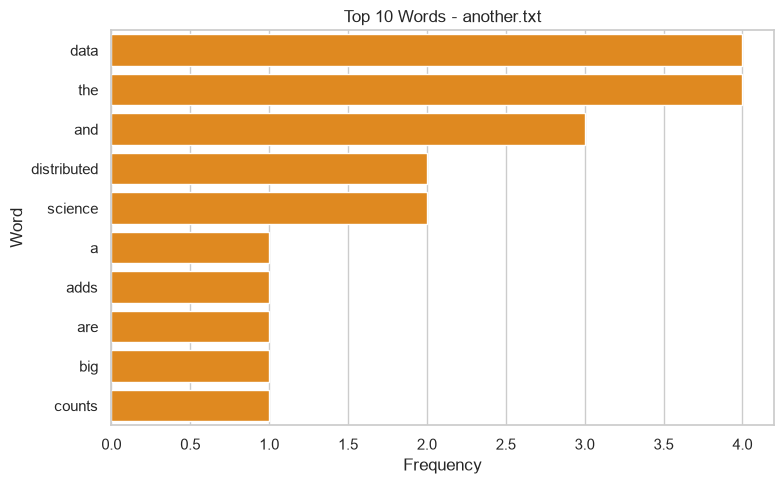

In [12]:
print("--- another.txt ---")
print((LOCAL_DIR / "another.txt").read_text())

run("hdfs dfs -mkdir -p /user/lab6/another")
run(f"hdfs dfs -put -f {LOCAL_DIR / 'another.txt'} /user/lab6/another/")

wc_another = run_wordcount("/user/lab6/another", "/user/lab6/output_another")
display(wc_another.head(10))

sns.barplot(data=wc_another.head(10), x="count", y="word", color="darkorange")
plt.title("Top 10 Words - another.txt")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()

### Exercise 4: Compare the output before and after modifying the input file

,word,before,after,change
0,hadoop,2,4,2
1,is,1,3,2
2,big,2,3,1
3,data,2,3,1
4,and,0,1,1
5,blocks,0,1,1
6,hdfs,0,1,1
7,in,0,1,1
8,open,0,1,1
9,scalable,0,1,1


,Metric,Before,After
0,Total words,14,28
1,Unique words,10,18


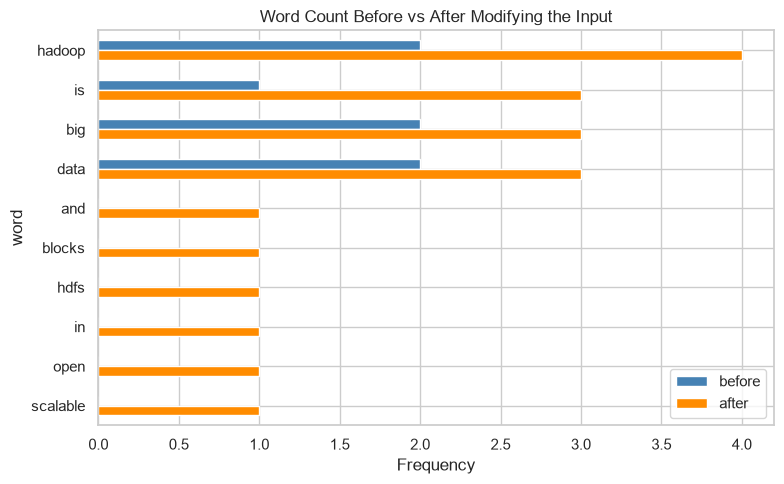

In [13]:
comparison = (
    wc_original.rename(columns={"count": "before"})
    .merge(wc_modified.rename(columns={"count": "after"}), on="word", how="outer")
    .fillna(0)
    .astype({"before": int, "after": int})
)
comparison["change"] = comparison["after"] - comparison["before"]
comparison = comparison.sort_values(["change", "after"], ascending=False).reset_index(drop=True)
display(comparison)

summary = pd.DataFrame({
    "Metric": ["Total words", "Unique words"],
    "Before": [wc_original["count"].sum(), len(wc_original)],
    "After": [wc_modified["count"].sum(), len(wc_modified)],
})
display(summary)

top = comparison.head(10).set_index("word")[["before", "after"]]
top.plot(kind="barh", figsize=(8, 5), color=["steelblue", "darkorange"])
plt.title("Word Count Before vs After Modifying the Input")
plt.xlabel("Frequency")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Words that already existed keep their old count plus any new occurrences, and new words are added with their own counts. Words that were not touched (for example `efficiently`, `framework`, `uses`) stay the same. MapReduce simply recomputes the whole output from the new input, so the result always matches the current file.

### Exercise 5: Role of the Mapper and Reducer in the Word Count application

**Mapper**
- Runs once per input split (part of the file), in parallel.
- Reads one line at a time, splits it into words, and emits `(word, 1)` for every word.
- Example: `Hadoop uses MapReduce` → `(hadoop, 1)`, `(uses, 1)`, `(mapreduce, 1)`.

**Shuffle and sort (done by Hadoop)**
- Groups all values with the same key: `(hadoop, [1, 1])`, `(big, [1, 1])`, ...

**Reducer**
- Receives each word once with the list of all its 1s.
- Adds them up and writes the final `(word, total)` to HDFS.
- Example: `(hadoop, [1, 1])` → `(hadoop, 2)`.

**Combiner**
- In this program the Reducer class is also used as a combiner. It pre-sums counts on the mapper side, so less data is sent over the network during the shuffle.

In short: the **Mapper splits and labels** the data, and the **Reducer aggregates** it.

---
## Observation

- The input text file was uploaded successfully to HDFS.
- The Word Count MapReduce program was compiled into a JAR and executed without errors.
- The Mapper generated intermediate `(word, 1)` key-value pairs.
- The Reducer calculated the total occurrence of each word.
- The output file (`part-r-00000`) stored the frequency of each word in HDFS.
- Modifying the input, skipping stopwords, and using another file all produced correct, updated counts.

## Result

The Word Count application was successfully implemented using Hadoop MapReduce. The program correctly counted the occurrences of each word in the input file and stored the output in HDFS.

## Conclusion

The experiment demonstrated the implementation of the Word Count application using the Hadoop MapReduce framework. The Mapper and Reducer worked together to process the input data and generate the word frequency count. This experiment provided practical knowledge of distributed data processing using Hadoop.